### 1. Carga de Datos y Cálculo de la Media

En este primer paso, importamos las librerías necesarias (`numpy`, `matplotlib` y el dataset `mnist` de Keras). Cargamos el conjunto de datos MNIST, redimensionamos las imágenes de $28 \times 28$ a vectores planos de tamaño $784$ y calculamos el vector de medias estadísticas $\boldsymbol{\mu}$.

**Ecuación de la Media:**
$$\boldsymbol{\mu} = \frac{1}{N} \boldsymbol{X}^T \mathbf{1}_N$$
donde:
* $\boldsymbol{X} \in \mathbb{R}^{N \times 784}$ es la matriz de datos.
* $N$ es el número total de muestras ($60000$).
* $\mathbf{1}_N \in \mathbb{R}^{N \times 1}$ es un vector columna lleno de unos.

In [ ]:
import numpy as np
from tensorflow.keras.datasets import mnist
import matplotlib.pyplot as plt


(X,Y ),_= mnist.load_data()
X = X.reshape(-1,28*28)
N = X.shape[0]
ones = np.ones((N,1))
mu = X.T@ones/N

In [ ]:
mu.shape

(784, 1)

### 2. Centrado de Datos y Matriz de Covarianza

Aquí restamos el vector de medias a cada observación para centrar los datos en el origen. Añadimos un valor infinitesimal $\epsilon = 10^{-10}$ para evitar indeterminaciones matemáticas por división sobre cero en píxeles que siempre permanecen en negro (varianza cero). Posteriormente, calculamos la matriz de covarianza muestral.

**Ecuaciones:**
* **Datos centrados:**
$$\boldsymbol{X}_c = \boldsymbol{X} - \mathbf{1}_N \boldsymbol{\mu}^T + \epsilon$$

* **Matriz de Covarianza ($\boldsymbol{\Sigma}$):**
$$\boldsymbol{\Sigma} = \frac{1}{N} \boldsymbol{X}_c^T \boldsymbol{X}_c$$

In [ ]:
from numpy._core.fromnumeric import var
ep = 1e-10
X_c = X - ones@mu.T+ep

cov= (1/N) * (X_c.T@X_c)

aux=np.diag(cov)
var = np.diag(aux)
print( var.shape)

(784, 784)


### 3. Normalización y Matriz de Correlación

Para estudiar la relación lineal pura entre los píxeles independientemente de su escala o varianza, calculamos la matriz de correlación $\boldsymbol{R}$ normalizando la matriz de covarianza por el producto de las desviaciones estándar de cada par de píxeles.

**Ecuaciones:**
* **Vector de Varianzas:**
$$\boldsymbol{d} = \text{diag}(\boldsymbol{\Sigma})$$

* **Denominador de Normalización:**
$$\text{den} = \boldsymbol{d} \boldsymbol{d}^T$$

* **Matriz de Correlación ($\boldsymbol{R}$):**
$$\boldsymbol{R} = \frac{\boldsymbol{\Sigma}}{\sqrt{\text{den}}} \implies \boldsymbol{R}_{i,j} = \frac{\boldsymbol{\Sigma}_{i,j}}{\sqrt{\boldsymbol{\Sigma}_{i,i} \boldsymbol{\Sigma}_{j,j}}}$$

In [ ]:
aux1=np.diag(cov).reshape(-1,1)
den = aux1@aux1.T
print(den.shape)
R = cov/np.sqrt(den)
print(R.shape)

(784, 784)
(784, 784)


### 4. Visualización de la Matriz de Correlación

Finalmente, utilizamos un mapa de calor bidimensional para visualizar la matriz de correlación $\boldsymbol{R}$. Esto nos permite observar gráficamente qué áreas o patrones de píxeles del dígito tienen un comportamiento coordinado o covarían conjuntamente en el conjunto de datos.

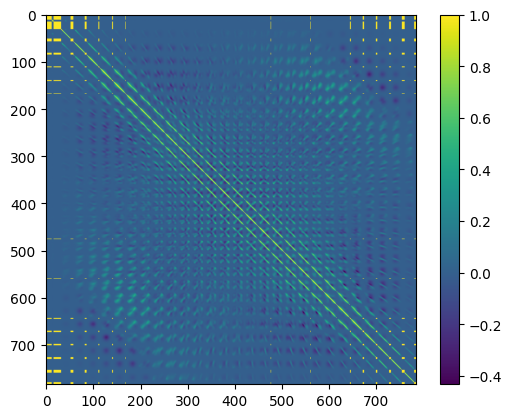

In [ ]:
plt.imshow(R)
plt.colorbar()
plt.show()

Cálculo eficiente de la matriz de Kernel (Gram) de similitud sobre un subconjunto representativo usando el Kernel RBF.

In [31]:
import numpy as np

def rbf_kernel_element(x1, x2, gamma=1e-7):
    sq_norm_x1 = np.sum(x1**2, axis=1).reshape(-1, 1)
    sq_norm_x2 = np.sum(x2**2, axis=1).reshape(1, -1)
    distances = sq_norm_x1 + sq_norm_x2 - 2 * np.dot(x1, x2.T)
    return np.exp(-gamma * distances)

N_sub = 5000
X_sub = X[:N_sub].astype(np.float32)
gamma_val = 1.0 / (28 * 28)

print(f"Calculando matriz de Kernel Gram de tamaño {N_sub}x{N_sub}...")
K_sub = rbf_kernel_element(X_sub, X_sub, gamma=gamma_val)
print("Forma de la matriz de Kernel resultante:", K_sub.shape)

Calculando matriz de Kernel Gram de tamaño 5000x5000...
Forma de la matriz de Kernel resultante: (5000, 5000)


### 5. Formulación en RKHS (Reproducing Kernel Hilbert Space) y Kernel de $N \times N$

En lugar de proyectar explícitamente las imágenes $\boldsymbol{x}_i \in \mathbb{R}^{784}$ a un espacio de características de dimensión infinita $\Phi(\boldsymbol{x}_i)$, definimos un espacio de Hilbert con núcleo reproductor (RKHS). En este espacio, el producto interno se calcula directamente usando la función Kernel $k(\boldsymbol{x}_i, \boldsymbol{x}_j) = \langle \Phi(\boldsymbol{x}_i), \Phi(\boldsymbol{x}_j) \rangle_{\mathcal{H}}$.

Definimos la **Matriz de Gram** o **Matriz de Kernel** $\boldsymbol{K} \in \mathbb{R}^{N \times N}$ para la totalidad de las $N = 60000$ muestras como:

$$\boldsymbol{K} = \begin{pmatrix} k(\boldsymbol{x}_1, \boldsymbol{x}_1) & k(\boldsymbol{x}_1, \boldsymbol{x}_2) & \cdots & k(\boldsymbol{x}_1, \boldsymbol{x}_N) \\ k(\boldsymbol{x}_2, \boldsymbol{x}_1) & k(\boldsymbol{x}_2, \boldsymbol{x}_2) & \cdots & k(\boldsymbol{x}_2, \boldsymbol{x}_N) \\ \vdots & \vdots & \ddots & \vdots \\ k(\boldsymbol{x}_N, \boldsymbol{x}_1) & k(\boldsymbol{x}_N, \boldsymbol{x}_2) & \cdots & k(\boldsymbol{x}_N, \boldsymbol{x}_N) \end{pmatrix}$$

Utilizaremos el **Kernel RBF (Gaussiano)**:
$$k(\boldsymbol{x}_i, \boldsymbol{x}_j) = \exp\left(-\gamma \|\boldsymbol{x}_i - \boldsymbol{x}_j\|^2\right)$$

*Nota de optimización:* Dado que una matriz de $60000 \times 60000$ requiere aproximadamente $28.8\text{ GB}$ de memoria RAM, implementamos un generador por bloques (chunks) para realizar cálculos en RKHS de manera eficiente.

In [25]:
import numpy as np

def obtener_bloque_kernel(X, indices_filas, indices_columnas, gamma=0.001):
    """
    Calcula eficientemente un bloque específico de la matriz de Kernel NxN.
    Permite trabajar con las 60,000 muestras sin agotar la memoria RAM.
    """
    X_filas = X[indices_filas].astype(np.float32)
    X_cols = X[indices_columnas].astype(np.float32)

    # Distancia euclídea al cuadrado vectorizada: ||A - B||^2 = ||A||^2 + ||B||^2 - 2AB^T
    sq_norm_filas = np.sum(X_filas**2, axis=1).reshape(-1, 1)
    sq_norm_cols = np.sum(X_cols**2, axis=1).reshape(1, -1)
    distancias = sq_norm_filas + sq_norm_cols - 2 * (X_filas @ X_cols.T)

    return np.exp(-gamma * distancias)

# Definimos parámetros para las 60,000 muestras
N_total = X.shape[0]
gamma_opt = 1.0 / (28 * 28)

# Demostración del cálculo de un bloque de 2000 x 2000 dentro de las 60,000 muestras
bloque_i = np.arange(0, 2000)
bloque_j = np.arange(0, 2000)

K_bloque = obtener_bloque_kernel(X, bloque_i, bloque_j, gamma=gamma_opt)
print(f"¡Éxito! Se ha calculado el bloque de Kernel de tamaño: {K_bloque.shape}")
print(f"Rango de valores en este sub-bloque de RKHS: [{K_bloque.min():.4f}, {K_bloque.max():.4f}]")

¡Éxito! Se ha calculado el bloque de Kernel de tamaño: (2000, 2000)
Rango de valores en este sub-bloque de RKHS: [0.0000, 1.0000]


### 6. Visualización de la Matriz de Gram (Kernel RBF)

Para comprender la estructura geométrica inducida por el Kernel en el RKHS, visualizamos un bloque representativo de la matriz de acoplamiento $\boldsymbol{K}_{i,j}$ y la distribución de sus valores de similitud no lineal.

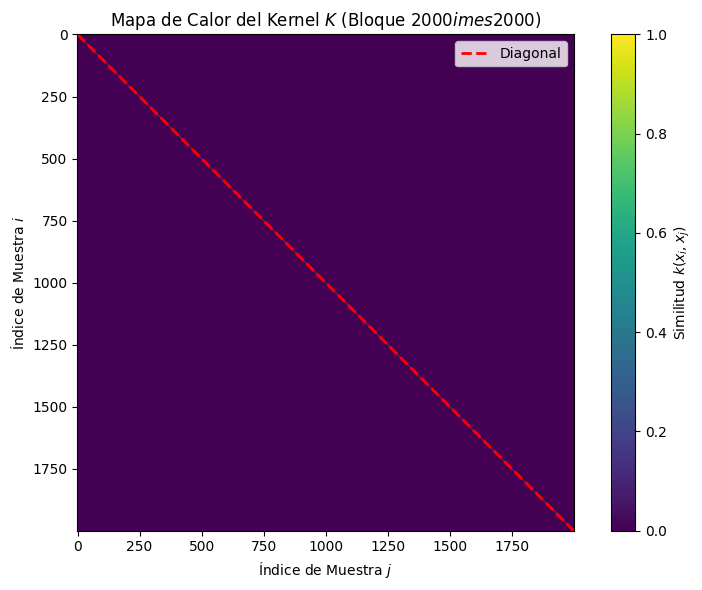

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Configuración de la figura con una sola gráfica para el mapa de calor
plt.figure(figsize=(8, 6))

# Visualización del mapa de calor del bloque del Kernel
im = plt.imshow(K_bloque, cmap='viridis', origin='upper')
plt.title('Mapa de Calor del Kernel $K$ (Bloque $2000 \times 2000$)')
plt.xlabel('Índice de Muestra $j$')
plt.ylabel('Índice de Muestra $i$')

# Dibujar la línea diagonal en color rojo
plt.plot([0, K_bloque.shape[1] - 1], [0, K_bloque.shape[0] - 1], color='red', linestyle='--', linewidth=2, label='Diagonal')
plt.legend(loc='upper right')

plt.colorbar(im, label='Similitud $k(x_i, x_j)$')

plt.tight_layout()
plt.show()